# Semana 2, Sessão 1: np.linalg na prática

In [20]:
import numpy as np

rng = np.random.default_rng(42)

Numpy solve, resolve "matrizes" de sistemas de equacoes lineares onde a sao as equacoes e b os resultados do tipo 1x + 2x(2) = 1,
3x + 5x(2) = 2. Devolve uma array com as solucoes

In [21]:
a = np.array([[1, 2], [3, 5]])
b = np.array([1, 2])
x = np.linalg.solve(a, b)
x

array([-1.,  1.])

Minimos Quadrados, voce da alguns pontos e ele tenta achar a linha que melhor se relaciona com esses pontos(interpolacao) algo parecido com uma regressao linear

In [22]:
x = np.array([0, 1, 2, 3])
y = np.array([-1, 0.2, 0.9, 2.1])


In [23]:
A = np.vstack([x, np.ones(len(x))]).T
A

array([[0., 1.],
       [1., 1.],
       [2., 1.],
       [3., 1.]])

In [24]:
m, c = np.linalg.lstsq(A, y)[0]
m, c


(np.float64(0.9999999999999999), np.float64(-0.9499999999999997))

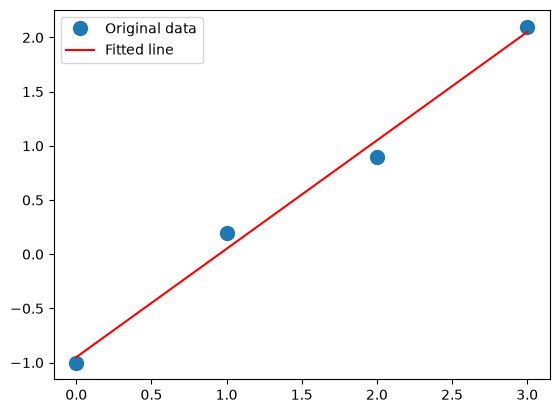

In [25]:
import matplotlib.pyplot as plt
_ = plt.plot(x, y, 'o', label='Original data', markersize=10)
_ = plt.plot(x, m*x + c, 'r', label='Fitted line')
_ = plt.legend()
plt.show()

numpy.linalg.eigh, retorna autovalores e autovetores de uma matriz

In [ ]:
a = np.array([[1, -2j], [2j, 5]])
a

array([[ 1.+0.j, -0.-2.j],
       [ 0.+2.j,  5.+0.j]])

In [27]:
eigenvalues, eigenvectors = np.linalg.eigh(a)
eigenvalues

array([0.17157288, 5.82842712])

In [28]:
eigenvectors


array([[-0.92387953+0.j        , -0.38268343+0.j        ],
       [ 0.        +0.38268343j,  0.        -0.92387953j]])

In [29]:
import numpy as np, warnings
warnings.simplefilter("ignore")
rng = np.random.default_rng(42)
n, w_real = 100, np.array([2.0, 3.0])
x1 = rng.normal(size=n); ruido_x = rng.normal(size=n); ruido_y = 0.1 * rng.normal(size=n)
print(f"{'eps':>6} {'cond(X)':>9} {'cond(XtX)':>10} | {'método':>6} {'w1':>12} {'w2':>12} {'w1+w2':>8} {'resíduo':>8}")
for eps in [1e-2, 1e-4, 1e-6, 1e-8]:
    X = np.column_stack([x1, x1 + eps * ruido_x])
    y = X @ w_real + ruido_y
    XtX, Xty = X.T @ X, X.T @ y
    res = {}
    try: res["inv"] = np.linalg.inv(XtX) @ Xty
    except np.linalg.LinAlgError: res["inv"] = None
    try: res["solve"] = np.linalg.solve(XtX, Xty)
    except np.linalg.LinAlgError: res["solve"] = None
    w, _, rank, sv = np.linalg.lstsq(X, y, rcond=None)
    res["lstsq"] = w
    for i, (m, w) in enumerate(res.items()):
        pre = f"{eps:>6.0e} {np.linalg.cond(X):>9.1e} {np.linalg.cond(XtX):>10.1e}" if i == 0 else " " * 27
        if w is None: print(f"{pre} | {m:>6} {'erro: matriz singular':>34}"); continue
        r = np.linalg.norm(X @ w - y)
        print(f"{pre} | {m:>6} {w[0]:>12.3f} {w[1]:>12.3f} {w.sum():>8.3f} {r:>8.4f}")
    print(f"{'':27} | lstsq: posto={rank}, valores singulares={np.round(sv, 8)}")
    print()
 


   eps   cond(X)  cond(XtX) | método           w1           w2    w1+w2  resíduo
 1e-02   1.6e+02    2.6e+04 |    inv        1.854        3.145    4.999   1.0211
                            |  solve        1.854        3.145    4.999   1.0211
                            |  lstsq        1.854        3.145    4.999   1.0211
                            | lstsq: posto=2, valores singulares=[10.95867969  0.06856495]

 1e-04   1.6e+04    2.5e+08 |    inv      -12.543       17.542    4.999   1.0211
                            |  solve      -12.543       17.542    4.999   1.0211
                            |  lstsq      -12.543       17.542    4.999   1.0211
                            | lstsq: posto=2, valores singulares=[1.09519809e+01 6.86070000e-04]

 1e-06   1.6e+06    2.5e+12 |    inv    -1452.193     1457.192    4.999   1.0211
                            |  solve    -1452.192     1457.192    4.999   1.0211
                            |  lstsq    -1452.203     1457.203    4.999   1.0211


## Conclusões: regressão linear com colunas colineares

Usei uma implementação gerada por IA para comparar três formas de resolver uma regressão linear (`inv`, `solve` e `lstsq`) com duas colunas quase colineares, variando o quanto elas se parecem. Tirei duas ideias principais:

### 1. Colinearidade é um problema dos dados

Quanto mais parecidas são as colunas, mais os pesos explodem. O modelo tenta explicar o ruído de `y`, e a única ferramenta que ele tem para isso é a pequena diferença entre as duas colunas. Quanto menor essa diferença, maior o peso necessário para que ela tenha algum impacto.

O problema da colinearidade é que não consigo saber ao certo quanto cada variável influencia o resultado final: os dados determinam bem o efeito conjunto (a soma dos pesos), mas não como ele se divide entre as colunas. Por isso os pesos individuais ficam instáveis e pouco confiáveis, embora a predição continue boa.

### 2. Existe também um problema de precisão numérica

Os métodos `inv` e `solve` montam uma matriz intermediária (XᵀX) para resolver o sistema. Essa matriz tem o número de condição elevado ao quadrado, então esses dois métodos perdem precisão antes do `lstsq`, que resolve diretamente sobre os dados originais. Esse problema só aparece quando as colunas ficam praticamente iguais, e é evitado usando o método adequado.